# Theme Alpha Q1 Theme Enhancement Validation

This notebook validates whether the theme-alpha-q1 low-volatility trend RiskParity sleeve is a robust theme-enhancement strategy or mostly a sample-period concentration result.

It continues from `theme-alpha-q1-strong-theme-screening-practice.ipynb`, but keeps validation separate from the first screening notebook.

Core questions:

1. Does LowVolTrend RiskParity still work after concentration caps?
2. Does it survive plausible transaction costs?
3. Is performance stable across rolling windows?
4. Do parameters selected in 2025 still work in 2026 YTD?


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q1-theme-enhancement-validation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2023-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0
REBALANCE_DAYS = 10
REBALANCE_ANCHOR = "2024-01-02"

BASELINE_ASSETS = ("510300.SS", "513100.SS", "518880.SS")
THEME_ASSETS = ("513100.SS", "512400.SS", "159995.SZ", "515880.SS", "518880.SS")
COMMON_SYMBOLS = tuple(dict.fromkeys(BASELINE_ASSETS + THEME_ASSETS))

SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "512400.SS": "有色金属ETF",
    "159995.SZ": "芯片ETF",
    "515880.SS": "通信ETF",
    "518880.SS": "黄金ETF",
}

BASE_RP_VOL = 20
BASE_MA = 120
BASE_MOM = 63
BASE_LOW_VOL_WINDOW = 60
BASE_TOP_N = 3

WINDOWS = {
    "2025_only": ("2025-01-01", "2025-12-31"),
    "2026_ytd": ("2026-01-01", None),
    "2025_to_date": ("2025-01-01", None),
}

print(f"Data start: {DATA_START}; request end: {END}")
print(f"Output dir: {OUTPUT_DIR}")


Data start: 2023-01-01; request end: 2026-06-24
Output dir: outputs/theme-alpha-q1-theme-enhancement-validation


## 1. Data Loading

Use the same ETF universe as the theme-alpha-q1 screening pass. The extra 2023-2024 history is only indicator warmup for moving averages, volatility, and rolling validation.


In [2]:
def flatten_yfinance(df):
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df


def download_ohlc(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, progress=False, auto_adjust=False, threads=False)
    df = flatten_yfinance(df)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    keep = [c for c in ["Open", "High", "Low", "Close", "Adj Close", "Volume"] if c in df.columns]
    df = df[keep].copy()
    df.columns = [c.lower().replace(" ", "_") for c in df.columns]
    df.index = pd.to_datetime(df.index).tz_localize(None)
    return df.sort_index()

market = {}
rows = []
for symbol in COMMON_SYMBOLS:
    market[symbol] = download_ohlc(symbol)
    rows.append({
        "symbol": symbol,
        "name": SYMBOL_NAMES[symbol],
        "first_date": market[symbol].index.min().date(),
        "last_date": market[symbol].index.max().date(),
        "rows": len(market[symbol]),
    })

data_availability = pd.DataFrame(rows)
data_availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(data_availability)

common_index = None
for symbol in COMMON_SYMBOLS:
    idx = market[symbol]["close"].dropna().index
    common_index = idx if common_index is None else common_index.intersection(idx)
common_index = pd.DatetimeIndex(common_index).sort_values()

close = pd.DataFrame({s: market[s]["close"].reindex(common_index) for s in COMMON_SYMBOLS}).dropna()
high = pd.DataFrame({s: market[s]["high"].reindex(close.index) for s in COMMON_SYMBOLS})
low = pd.DataFrame({s: market[s]["low"].reindex(close.index) for s in COMMON_SYMBOLS})
returns = close.pct_change().fillna(0.0)

print(f"Common sample: {close.index.min().date()} to {close.index.max().date()}, rows={len(close)}")
display(close.tail())


,symbol,name,first_date,last_date,rows
0,510300.SS,沪深300ETF,2023-01-03,2026-06-22,836
1,513100.SS,纳指100ETF,2023-01-03,2026-06-22,837
2,518880.SS,黄金ETF,2023-01-03,2026-06-22,836
3,512400.SS,有色金属ETF,2023-01-03,2026-06-22,836
4,159995.SZ,芯片ETF,2023-01-03,2026-06-22,836
5,515880.SS,通信ETF,2023-01-03,2026-06-22,836


Common sample: 2023-01-03 to 2026-06-22, rows=836


,510300.SS,513100.SS,518880.SS,512400.SS,159995.SZ,515880.SS
Date,,,,,,
2026-06-15,4.919,2.258,8.928,2.063,2.514,1.689
2026-06-16,4.910,2.280,8.949,2.049,2.536,1.729
2026-06-17,4.958,2.279,8.957,2.045,2.690,1.758
2026-06-18,4.984,2.266,8.908,2.050,2.816,1.822
2026-06-22,5.091,2.250,8.716,2.155,2.920,1.859


## 2. Strategy And Cost Helpers

All signals are computed on rebalance dates and applied one trading day later. Transaction cost is charged on one-way turnover, including cash movement.


In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(20):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if capacity.sum() <= 1e-12 or excess <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        if base.sum() <= 1e-12:
            add = excess * capacity / capacity.sum()
        else:
            add = excess * base / base.sum()
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def equal_weight(eligible, universe, cap=None):
    eligible = [sym for sym in eligible if sym in universe]
    if not eligible:
        return normalize_weights({}, universe)
    raw = {sym: 1.0 / len(eligible) for sym in eligible}
    return apply_cap(raw, universe, cap)


def risk_parity_weight(date, eligible, universe, vol_window=BASE_RP_VOL, cap=None):
    eligible = [sym for sym in eligible if sym in universe]
    if not eligible:
        return normalize_weights({}, universe)
    loc = close.index.get_loc(date)
    if loc < vol_window:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - vol_window + 1 : loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    return apply_cap(raw, universe, cap)


def rebalance_set(index, every=REBALANCE_DAYS, anchor=REBALANCE_ANCHOR):
    idx = pd.DatetimeIndex(index)
    anchor = pd.Timestamp(anchor)
    start_pos = idx.searchsorted(anchor)
    return set(pd.DatetimeIndex(idx[start_pos::every]))


def build_weights(universe, selector, allocator):
    dates = rebalance_set(close.index)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in dates:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def turnover_from_weights(signal_weights, universe):
    actual = signal_weights[list(universe) + ["CASH"]].shift(1).fillna(0.0)
    return 0.5 * actual.diff().abs().sum(axis=1).fillna(actual.abs().sum(axis=1))


def backtest_from_weights(name, universe, signal_weights, cost_bps=0.0):
    asset_weights = signal_weights[list(universe)].shift(1).fillna(0.0)
    gross_returns = (asset_weights * returns[list(universe)]).sum(axis=1)
    turnover = turnover_from_weights(signal_weights, universe)
    cost = turnover * (cost_bps / 10000.0)
    net_returns = gross_returns - cost
    nav = (1.0 + net_returns).cumprod() * INITIAL_NAV
    return {
        "name": name,
        "universe": tuple(universe),
        "weights": signal_weights,
        "gross_returns": gross_returns,
        "returns": net_returns,
        "turnover": turnover,
        "cost_bps": cost_bps,
        "nav": nav.rename(name),
    }


def run_strategy(name, universe, selector, allocator, cost_bps=0.0):
    weights = build_weights(universe, selector, allocator)
    return backtest_from_weights(name, universe, weights, cost_bps)


def all_assets(universe):
    return lambda _date: list(universe)


def rp_allocator(universe, vol_window=BASE_RP_VOL, cap=None):
    return lambda date, eligible: risk_parity_weight(date, eligible, universe, vol_window, cap)


def ew_allocator(universe, cap=None):
    return lambda _date, eligible: equal_weight(eligible, universe, cap)


def low_vol_trend_selector(universe, ma_window=BASE_MA, mom_window=BASE_MOM, vol_window=BASE_LOW_VOL_WINDOW, top_n=BASE_TOP_N):
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(ma_window, mom_window, vol_window)
        if loc < warmup:
            return []
        symbols = list(universe)
        price = close.iloc[loc][symbols]
        ma = close.iloc[loc - ma_window + 1 : loc + 1][symbols].mean()
        mom = price / close.iloc[loc - mom_window][symbols] - 1.0
        vols = returns.iloc[loc - vol_window + 1 : loc + 1][symbols].std(ddof=1)
        eligible = price.index[(price > ma) & (mom > 0)].tolist()
        if not eligible:
            return []
        return vols[eligible].sort_values().head(top_n).index.tolist()
    return select


def static_mix(name, weights_map, cost_bps=0.0):
    universe = tuple(weights_map.keys())
    total = sum(weights_map.values())
    weights = pd.DataFrame(0.0, index=close.index, columns=list(universe) + ["CASH"])
    for sym, val in weights_map.items():
        weights[sym] = val / total
    return backtest_from_weights(name, universe, weights, cost_bps)


def buy_hold(name, symbol, cost_bps=0.0):
    return static_mix(name, {symbol: 1.0}, cost_bps)


## 3. Metrics


In [4]:
def window_slice(series, start, end=None):
    out = series.loc[pd.Timestamp(start):]
    if end is not None:
        out = out.loc[:pd.Timestamp(end)]
    return out.dropna()


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def drawdown(nav):
    return nav / nav.cummax() - 1.0


def max_drawdown_from_returns(r):
    if len(r) == 0:
        return np.nan
    return drawdown(nav_from_returns(r)).min()


def metrics_row(name, r, weights=None, turnover=None):
    r = r.dropna()
    if len(r) == 0:
        return {"策略": name}
    nav = nav_from_returns(r)
    total = nav.iloc[-1] / INITIAL_NAV - 1.0
    ann = (1.0 + total) ** (TRADING_DAYS / len(r)) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS) if len(r) > 1 else np.nan
    mdd = drawdown(nav).min()
    sharpe = ann / vol if pd.notna(vol) and vol > 0 else np.nan
    calmar = ann / abs(mdd) if pd.notna(mdd) and mdd < 0 else np.nan
    downside = r[r < 0].std(ddof=1) * np.sqrt(TRADING_DAYS)
    sortino = ann / downside if pd.notna(downside) and downside > 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    wins = monthly[monthly > 0]
    losses = monthly[monthly < 0]
    row = {
        "策略": name,
        "累计收益": total,
        "年化收益": ann,
        "年化波动": vol,
        "最大回撤": mdd,
        "夏普": sharpe,
        "卡玛": calmar,
        "索提诺": sortino,
        "月胜率": (monthly > 0).mean() if len(monthly) else np.nan,
        "平均盈利月": wins.mean() if len(wins) else np.nan,
        "平均亏损月": losses.mean() if len(losses) else np.nan,
        "最好月份": monthly.max() if len(monthly) else np.nan,
        "最差月份": monthly.min() if len(monthly) else np.nan,
    }
    if turnover is not None:
        t = turnover.reindex(r.index).fillna(0.0)
        row["年化换手"] = t.mean() * TRADING_DAYS
        row["总换手"] = t.sum()
    if weights is not None and not weights.empty:
        w = weights.reindex(r.index).ffill().fillna(0.0)
        row["平均现金"] = w["CASH"].mean() if "CASH" in w else 0.0
        row["当前现金"] = w["CASH"].iloc[-1] if "CASH" in w else 0.0
        asset_cols = [c for c in w.columns if c != "CASH"]
        row["平均最大单资产权重"] = w[asset_cols].max(axis=1).mean() if asset_cols else np.nan
        row["当前最大单资产权重"] = w[asset_cols].iloc[-1].max() if asset_cols else np.nan
    return row


def evaluate_portfolios(portfolios, window_name, start, end=None):
    rows = []
    navs = {}
    rets = {}
    for name, port in portfolios.items():
        r = window_slice(port["returns"], start, end)
        if len(r) < 20:
            continue
        rows.append(metrics_row(name, r, port["weights"], port["turnover"]))
        navs[name] = nav_from_returns(r)
        rets[name] = r
    summary = pd.DataFrame(rows).set_index("策略").sort_values("夏普", ascending=False)
    nav_df = pd.DataFrame(navs)
    ret_df = pd.DataFrame(rets)
    summary.to_csv(OUTPUT_DIR / f"summary_{window_name}.csv", encoding="utf-8-sig")
    ret_df.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0).to_csv(OUTPUT_DIR / f"monthly_returns_{window_name}.csv", encoding="utf-8-sig")
    nav_df.apply(drawdown).to_csv(OUTPUT_DIR / f"underwater_{window_name}.csv", encoding="utf-8-sig")
    return summary, nav_df, ret_df


## 4. Base Validation Portfolios

The capped variants answer whether LowVolTrend's result survives after limiting single-asset concentration. If too few assets pass the filter, capped leftover capital stays in cash.


In [5]:
def build_validation_portfolios(cost_bps=0.0):
    return {
        "原三资产RiskParity": run_strategy("原三资产RiskParity", BASELINE_ASSETS, all_assets(BASELINE_ASSETS), rp_allocator(BASELINE_ASSETS), cost_bps),
        "主题等权": run_strategy("主题等权", THEME_ASSETS, all_assets(THEME_ASSETS), ew_allocator(THEME_ASSETS), cost_bps),
        "主题RiskParity": run_strategy("主题RiskParity", THEME_ASSETS, all_assets(THEME_ASSETS), rp_allocator(THEME_ASSETS), cost_bps),
        "主题RiskParity_cap40": run_strategy("主题RiskParity_cap40", THEME_ASSETS, all_assets(THEME_ASSETS), rp_allocator(THEME_ASSETS, cap=0.40), cost_bps),
        "低波趋势RP": run_strategy("低波趋势RP", THEME_ASSETS, low_vol_trend_selector(THEME_ASSETS), rp_allocator(THEME_ASSETS), cost_bps),
        "低波趋势RP_cap60": run_strategy("低波趋势RP_cap60", THEME_ASSETS, low_vol_trend_selector(THEME_ASSETS), rp_allocator(THEME_ASSETS, cap=0.60), cost_bps),
        "低波趋势RP_cap50": run_strategy("低波趋势RP_cap50", THEME_ASSETS, low_vol_trend_selector(THEME_ASSETS), rp_allocator(THEME_ASSETS, cap=0.50), cost_bps),
        "低波趋势RP_cap40": run_strategy("低波趋势RP_cap40", THEME_ASSETS, low_vol_trend_selector(THEME_ASSETS), rp_allocator(THEME_ASSETS, cap=0.40), cost_bps),
        "纯纳指ETF": buy_hold("纯纳指ETF", "513100.SS", cost_bps),
        "纯黄金ETF": buy_hold("纯黄金ETF", "518880.SS", cost_bps),
        "60_40沪深300黄金": static_mix("60_40沪深300黄金", {"510300.SS": 0.6, "518880.SS": 0.4}, cost_bps),
    }

base_portfolios = build_validation_portfolios(cost_bps=0.0)

window_outputs = {}
for window_name, (start, end) in WINDOWS.items():
    summary, navs, rets = evaluate_portfolios(base_portfolios, window_name, start, end)
    window_outputs[window_name] = {"summary": summary, "navs": navs, "returns": rets}
    print()
    print(f"=== {window_name}: {start} to {end or 'latest'} ===")
    display(summary[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "年化换手", "平均现金", "平均最大单资产权重"]].round(4))

# Export latest and average weights for the full 2025-to-date window.
latest_rows = []
avg_rows = []
for name, port in base_portfolios.items():
    w = port["weights"].loc[pd.Timestamp("2025-01-01"):]
    asset_cols = [c for c in w.columns if c != "CASH"]
    latest_rows.append({"策略": name, **{SYMBOL_NAMES.get(c, c): w[c].iloc[-1] for c in asset_cols}, "现金": w["CASH"].iloc[-1]})
    avg_rows.append({"策略": name, **{SYMBOL_NAMES.get(c, c): w[c].mean() for c in asset_cols}, "现金": w["CASH"].mean()})
latest_weights = pd.DataFrame(latest_rows).set_index("策略")
average_weights = pd.DataFrame(avg_rows).set_index("策略")
latest_weights.to_csv(OUTPUT_DIR / "latest_weights_2025_to_date.csv", encoding="utf-8-sig")
average_weights.to_csv(OUTPUT_DIR / "average_weights_2025_to_date.csv", encoding="utf-8-sig")
display(latest_weights.round(4))



=== 2025_only: 2025-01-01 to 2025-12-31 ===


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,,
低波趋势RP,0.6104,0.6424,0.1648,-0.0681,3.8990,9.4271,6.6774,0.0000,0.5057
低波趋势RP_cap60,0.5841,0.6145,0.1604,-0.0639,3.8321,9.6179,6.2537,0.0000,0.4827
主题RiskParity,0.6245,0.6574,0.1770,-0.1008,3.7143,6.5243,2.2635,0.0000,0.3353
主题RiskParity_cap40,0.6158,0.6481,0.1780,-0.1008,3.6412,6.4317,2.1010,0.0000,0.3300
低波趋势RP_cap50,0.5472,0.5754,0.1613,-0.0731,3.5671,7.8719,5.9930,0.0000,0.4588
低波趋势RP_cap40,0.5134,0.5396,0.1551,-0.0660,3.4793,8.1761,5.4366,0.0188,0.3972
主题等权,0.6744,0.7105,0.2176,-0.1396,3.2652,5.0878,0.0000,0.0000,0.2000
纯黄金ETF,0.5690,0.5985,0.1904,-0.1153,3.1426,5.1924,0.0000,0.0000,1.0000
原三资产RiskParity,0.3649,0.3826,0.1279,-0.0658,2.9916,5.8118,2.3213,0.0000,0.4403



=== 2026_ytd: 2026-01-01 to latest ===


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,,
低波趋势RP_cap50,0.2573,0.6896,0.3568,-0.2385,1.9328,2.8910,4.9745,0.0000,0.4596
低波趋势RP,0.2474,0.6595,0.3470,-0.2385,1.9007,2.7646,5.5000,0.0000,0.5092
低波趋势RP_cap60,0.2359,0.6246,0.3489,-0.2385,1.7902,2.6184,5.0032,0.0000,0.4924
低波趋势RP_cap40,0.2284,0.6020,0.3376,-0.2378,1.7830,2.5321,4.7914,0.0364,0.4000
纯纳指ETF,0.1817,0.4660,0.2679,-0.1326,1.7396,3.5130,0.0000,0.0000,1.0000
主题RiskParity,0.1373,0.3428,0.2920,-0.2489,1.1739,1.3773,2.4676,0.0000,0.3461
主题RiskParity_cap40,0.1362,0.3398,0.2929,-0.2496,1.1601,1.3614,2.2415,0.0000,0.3297
主题等权,0.1512,0.3806,0.3381,-0.2794,1.1257,1.3622,0.0000,0.0000,0.2000
原三资产RiskParity,0.0658,0.1572,0.2060,-0.1278,0.7630,1.2300,1.5388,0.0000,0.4346



=== 2025_to_date: 2025-01-01 to latest ===


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,,
低波趋势RP,1.0088,0.6477,0.2367,-0.2385,2.7365,2.7153,6.3095,0.0000,0.5068
低波趋势RP_cap60,0.9579,0.6177,0.2355,-0.2385,2.6227,2.5894,5.8629,0.0000,0.4857
低波趋势RP_cap50,0.9453,0.6102,0.2396,-0.2385,2.5468,2.5582,5.6747,0.0000,0.4590
主题RiskParity,0.8476,0.5519,0.2191,-0.2489,2.5186,2.2177,2.3273,0.0000,0.3387
主题RiskParity_cap40,0.8358,0.5448,0.2201,-0.2496,2.4759,2.1829,2.1449,0.0000,0.3299
低波趋势RP_cap40,0.8591,0.5588,0.2279,-0.2378,2.4524,2.3504,5.2350,0.0243,0.3981
主题等权,0.9275,0.5997,0.2608,-0.2794,2.2991,2.1463,0.0000,0.0000,0.2000
原三资产RiskParity,0.4547,0.3078,0.1563,-0.1278,1.9693,2.4087,2.0768,0.0000,0.4385
60_40沪深300黄金,0.3590,0.2456,0.1658,-0.1442,1.4812,1.7028,0.0000,0.0000,0.6000


,沪深300ETF,纳指100ETF,黄金ETF,现金,有色金属ETF,芯片ETF,通信ETF
策略,,,,,,,
原三资产RiskParity,0.459,0.2203,0.3207,0.0,NaN,NaN,NaN
主题等权,NaN,0.2000,0.2000,0.0,0.2000,0.2000,0.2000
主题RiskParity,NaN,0.2144,0.3121,0.0,0.1885,0.1430,0.1420
主题RiskParity_cap40,NaN,0.2144,0.3121,0.0,0.1885,0.1430,0.1420
低波趋势RP,NaN,0.5998,0.0000,0.0,0.0000,0.4002,0.0000
低波趋势RP_cap60,NaN,0.5998,0.0000,0.0,0.0000,0.4002,0.0000
低波趋势RP_cap50,NaN,0.5000,0.0000,0.0,0.0000,0.5000,0.0000
低波趋势RP_cap40,NaN,0.4000,0.0667,0.0,0.0667,0.4000,0.0667
纯纳指ETF,NaN,1.0000,NaN,0.0,NaN,NaN,NaN


## 5. Transaction Cost Sensitivity

Costs are charged on one-way turnover. This is intentionally simple: it is a first robustness check, not an execution simulator.


In [6]:
def cost_sensitivity_for_window(window_name, start, end=None, costs=(0, 5, 10, 20)):
    rows = []
    for cost_bps in costs:
        ports = build_validation_portfolios(cost_bps=cost_bps)
        for name, port in ports.items():
            if name not in ["原三资产RiskParity", "主题RiskParity", "主题RiskParity_cap40", "低波趋势RP", "低波趋势RP_cap60", "低波趋势RP_cap50", "低波趋势RP_cap40"]:
                continue
            r = window_slice(port["returns"], start, end)
            row = metrics_row(name, r, port["weights"], port["turnover"])
            row["成本bps"] = cost_bps
            rows.append(row)
    df = pd.DataFrame(rows).set_index(["成本bps", "策略"]).sort_index()
    df.to_csv(OUTPUT_DIR / f"cost_sensitivity_{window_name}.csv", encoding="utf-8-sig")
    return df

cost_tables = {}
for window_name, (start, end) in WINDOWS.items():
    cost_tables[window_name] = cost_sensitivity_for_window(window_name, start, end)
    print()
    print(f"Cost sensitivity - {window_name}")
    display(cost_tables[window_name][["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "年化换手"]].round(4))



Cost sensitivity - 2025_only


累计收益    年化收益    最大回撤      夏普      卡玛    年化换手
成本bps 策略                                                                
0     主题RiskParity        0.6245  0.6574 -0.1008  3.7143  6.5243  2.2635
      主题RiskParity_cap40  0.6158  0.6481 -0.1008  3.6412  6.4317  2.1010
      低波趋势RP              0.6104  0.6424 -0.0681  3.8990  9.4271  6.6774
      低波趋势RP_cap40        0.5134  0.5396 -0.0660  3.4793  8.1761  5.4366
      低波趋势RP_cap50        0.5472  0.5754 -0.0731  3.5671  7.8719  5.9930
      低波趋势RP_cap60        0.5841  0.6145 -0.0639  3.8321  9.6179  6.2537
      原三资产RiskParity      0.3649  0.3826 -0.0658  2.9916  5.8118  2.3213
5     主题RiskParity        0.6228  0.6556 -0.1009  3.7039  6.4981  2.2635
      主题RiskParity_cap40  0.6141  0.6464 -0.1009  3.6316  6.4071  2.1010
      低波趋势RP              0.6052  0.6369 -0.0683  3.8665  9.3278  6.6774
      低波趋势RP_cap40        0.5095  0.5354 -0.0661  3.4520  8.1019  5.4366
      低波趋势RP_cap50        0.5428  0.5707 -0.0732  3.5375  7.7996  5.9930
      低波趋势RP_cap60        0.5794  0.6095 -0.0640  3.8006  9.5286  6.2537
      原三资产RiskParity      0.3634  0.3810 -0.0660  2.9791  5.7729  2.3213
10    主题RiskParity        0.6210  0.6537 -0.1010  3.6934  6.4720  2.2635
      主题RiskParity_cap40  0.6125  0.6447 -0.1010  3.6219  6.3825  2.1010
      低波趋势RP              0.6001  0.6315 -0.0684  3.8341  9.2292  6.6774
      低波趋势RP_cap40        0.5055  0.5312 -0.0662  3.4246  8.0281  5.4366
      低波趋势RP_cap50        0.5383  0.5660 -0.0732  3.5080  7.7277  5.9930
      低波趋势RP_cap60        0.5747  0.6045 -0.0640  3.7691  9.4397  6.2537
      原三资产RiskParity      0.3619  0.3794 -0.0662  2.9666  5.7342  2.3213
20    主题RiskParity        0.6175  0.6500 -0.1012  3.6725  6.4201  2.2635
      主题RiskParity_cap40  0.6093  0.6412 -0.1012  3.6027  6.3337  2.1010
      低波趋势RP              0.5899  0.6207 -0.0687  3.7692  9.0339  6.6774
      低波趋势RP_cap40        0.4977  0.5229 -0.0663  3.3700  7.8814  5.4366
      低波趋势RP_cap50        0.5295  0.5566 -0.0734  3.4490  7.5847  5.9930
      低波趋势RP_cap60        0.5652  0.5945 -0.0642  3.7062  9.2622  6.2537
      原三资产RiskParity      0.3588  0.3762 -0.0665  2.9416  5.6575  2.3213


Cost sensitivity - 2026_ytd


累计收益    年化收益    最大回撤      夏普      卡玛    年化换手
成本bps 策略                                                                
0     主题RiskParity        0.1373  0.3428 -0.2489  1.1739  1.3773  2.4676
      主题RiskParity_cap40  0.1362  0.3398 -0.2496  1.1601  1.3614  2.2415
      低波趋势RP              0.2474  0.6595 -0.2385  1.9007  2.7646  5.5000
      低波趋势RP_cap40        0.2284  0.6020 -0.2378  1.7830  2.5321  4.7914
      低波趋势RP_cap50        0.2573  0.6896 -0.2385  1.9328  2.8910  4.9745
      低波趋势RP_cap60        0.2359  0.6246 -0.2385  1.7902  2.6184  5.0032
      原三资产RiskParity      0.0658  0.1572 -0.1278  0.7630  1.2300  1.5388
5     主题RiskParity        0.1367  0.3411 -0.2490  1.1681  1.3698  2.4676
      主题RiskParity_cap40  0.1356  0.3383 -0.2497  1.1550  1.3547  2.2415
      低波趋势RP              0.2460  0.6550 -0.2387  1.8882  2.7441  5.5000
      低波趋势RP_cap40        0.2271  0.5983 -0.2378  1.7723  2.5155  4.7914
      低波趋势RP_cap50        0.2559  0.6855 -0.2387  1.9216  2.8720  4.9745
      低波趋势RP_cap60        0.2346  0.6206 -0.2387  1.7790  2.6001  5.0032
      原三资产RiskParity      0.0654  0.1563 -0.1279  0.7587  1.2220  1.5388
10    主题RiskParity        0.1361  0.3395 -0.2492  1.1624  1.3623  2.4676
      主题RiskParity_cap40  0.1351  0.3368 -0.2498  1.1498  1.3481  2.2415
      低波趋势RP              0.2445  0.6505 -0.2388  1.8756  2.7238  5.5000
      低波趋势RP_cap40        0.2259  0.5945 -0.2379  1.7617  2.4989  4.7914
      低波趋势RP_cap50        0.2546  0.6813 -0.2388  1.9103  2.8530  4.9745
      低波趋势RP_cap60        0.2333  0.6166 -0.2388  1.7679  2.5819  5.0032
      原三资产RiskParity      0.0651  0.1554 -0.1280  0.7544  1.2141  1.5388
20    主题RiskParity        0.1348  0.3361 -0.2495  1.1510  1.3473  2.4676
      主题RiskParity_cap40  0.1340  0.3338 -0.2501  1.1396  1.3348  2.2415
      低波趋势RP              0.2415  0.6415 -0.2391  1.8506  2.6832  5.5000
      低波趋势RP_cap40        0.2233  0.5870 -0.2380  1.7404  2.4659  4.7914
      低波趋势RP_cap50        0.2519  0.6731 -0.2391  1.8879  2.8153  4.9745
      低波趋势RP_cap60        0.2306  0.6086 -0.2391  1.7456  2.5456  5.0032
      原三资产RiskParity      0.0644  0.1536 -0.1282  0.7457  1.1984  1.5388


Cost sensitivity - 2025_to_date


累计收益    年化收益    最大回撤      夏普      卡玛    年化换手
成本bps 策略                                                                
0     主题RiskParity        0.8476  0.5519 -0.2489  2.5186  2.2177  2.3273
      主题RiskParity_cap40  0.8358  0.5448 -0.2496  2.4759  2.1829  2.1449
      低波趋势RP              1.0088  0.6477 -0.2385  2.7365  2.7153  6.3095
      低波趋势RP_cap40        0.8591  0.5588 -0.2378  2.4524  2.3504  5.2350
      低波趋势RP_cap50        0.9453  0.6102 -0.2385  2.5468  2.5582  5.6747
      低波趋势RP_cap60        0.9579  0.6177 -0.2385  2.6227  2.5894  5.8629
      原三资产RiskParity      0.4547  0.3078 -0.1278  1.9693  2.4087  2.0768
5     主题RiskParity        0.8446  0.5501 -0.2490  2.5103  2.2091  2.3273
      主题RiskParity_cap40  0.8331  0.5432 -0.2497  2.4684  2.1752  2.1449
      低波趋势RP              1.0000  0.6425 -0.2387  2.7152  2.6921  6.3095
      低波趋势RP_cap40        0.8523  0.5548 -0.2378  2.4350  2.3326  5.2350
      低波趋势RP_cap50        0.9376  0.6057 -0.2387  2.5281  2.5377  5.6747
      低波趋势RP_cap60        0.9499  0.6129 -0.2387  2.6030  2.5682  5.8629
      原三资产RiskParity      0.4526  0.3064 -0.1279  1.9606  2.3962  2.0768
10    主题RiskParity        0.8416  0.5483 -0.2492  2.5021  2.2004  2.3273
      主题RiskParity_cap40  0.8303  0.5415 -0.2498  2.4609  2.1675  2.1449
      低波趋势RP              0.9913  0.6374 -0.2388  2.6940  2.6691  6.3095
      低波趋势RP_cap40        0.8456  0.5507 -0.2379  2.4176  2.3149  5.2350
      低波趋势RP_cap50        0.9300  0.6011 -0.2388  2.5094  2.5173  5.6747
      低波趋势RP_cap60        0.9419  0.6082 -0.2388  2.5833  2.5470  5.8629
      原三资产RiskParity      0.4505  0.3051 -0.1280  1.9519  2.3837  2.0768
20    主题RiskParity        0.8356  0.5447 -0.2495  2.4857  2.1832  2.3273
      主题RiskParity_cap40  0.8249  0.5382 -0.2501  2.4459  2.1522  2.1449
      低波趋势RP              0.9739  0.6271 -0.2391  2.6517  2.6232  6.3095
      低波趋势RP_cap40        0.8322  0.5426 -0.2380  2.3828  2.2796  5.2350
      低波趋势RP_cap50        0.9148  0.5921 -0.2391  2.4722  2.4766  5.6747
      低波趋势RP_cap60        0.9262  0.5989 -0.2391  2.5441  2.5050  5.8629
      原三资产RiskParity      0.4463  0.3024 -0.1282  1.9346  2.3589  2.0768

## 6. Rolling Window Diagnostics

Rolling checks ask whether the advantage appears repeatedly or only in one lucky segment.


,策略,rolling_days,平均滚动收益,滚动收益胜率,平均滚动Sharpe,滚动Sharpe为正比例,最差滚动回撤
0,主题RiskParity,63,0.1109,0.8172,4.0561,0.8172,-0.2489
1,主题RiskParity,126,0.2839,1.0000,3.7824,1.0000,-0.2489
2,主题RiskParity,252,0.5677,1.0000,2.7168,1.0000,-0.2489
3,低波趋势RP,63,0.1094,0.8759,3.8605,0.8759,-0.2385
4,低波趋势RP,126,0.2716,1.0000,3.6071,1.0000,-0.2385
5,低波趋势RP,252,0.5628,1.0000,2.5763,1.0000,-0.2385
6,低波趋势RP_cap40,63,0.0956,0.8448,3.4458,0.8448,-0.2378
7,低波趋势RP_cap40,126,0.2451,1.0000,3.3266,1.0000,-0.2378
8,低波趋势RP_cap40,252,0.4948,1.0000,2.3326,1.0000,-0.2378
9,低波趋势RP_cap50,63,0.1007,0.8724,3.6524,0.8724,-0.2385


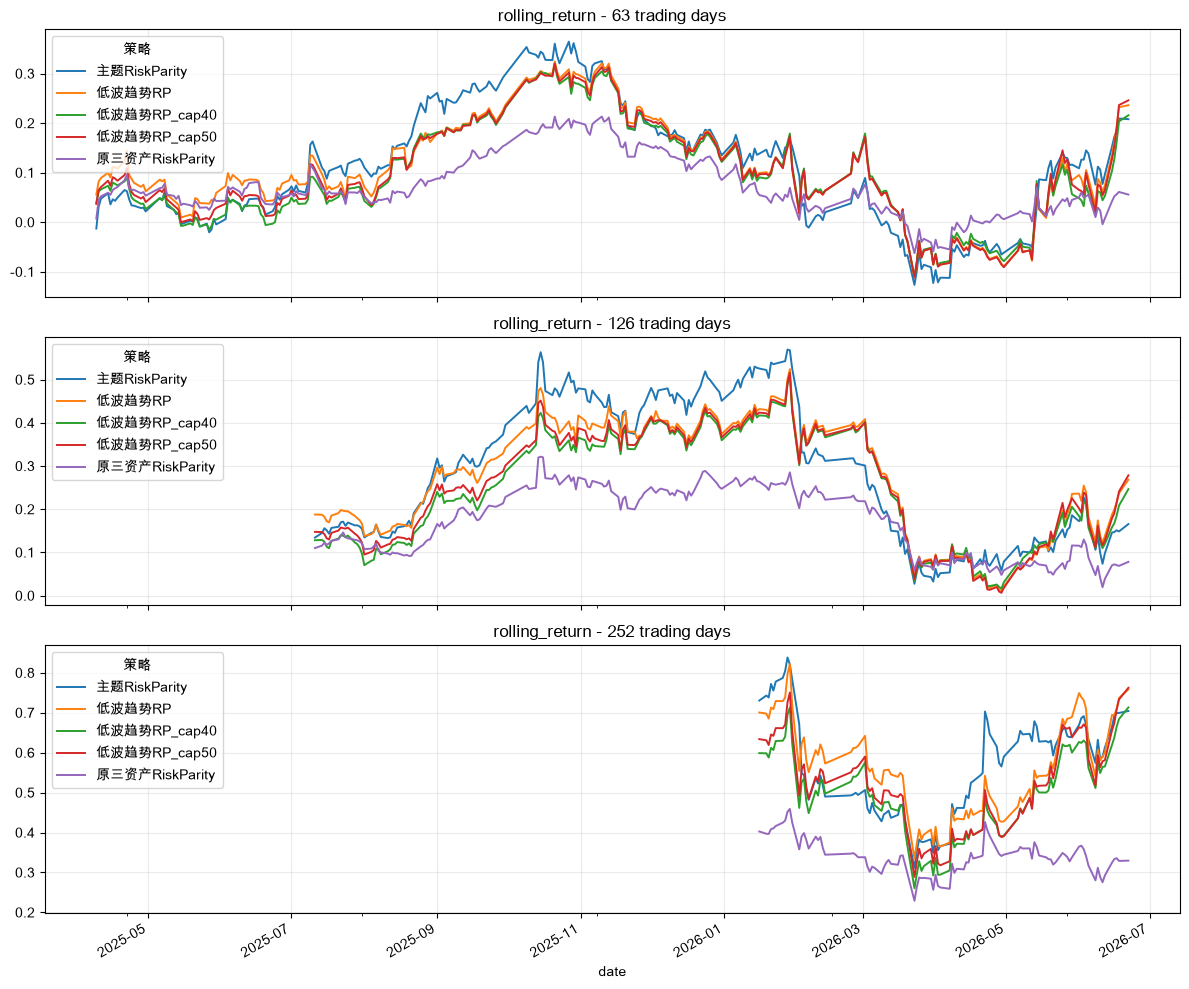

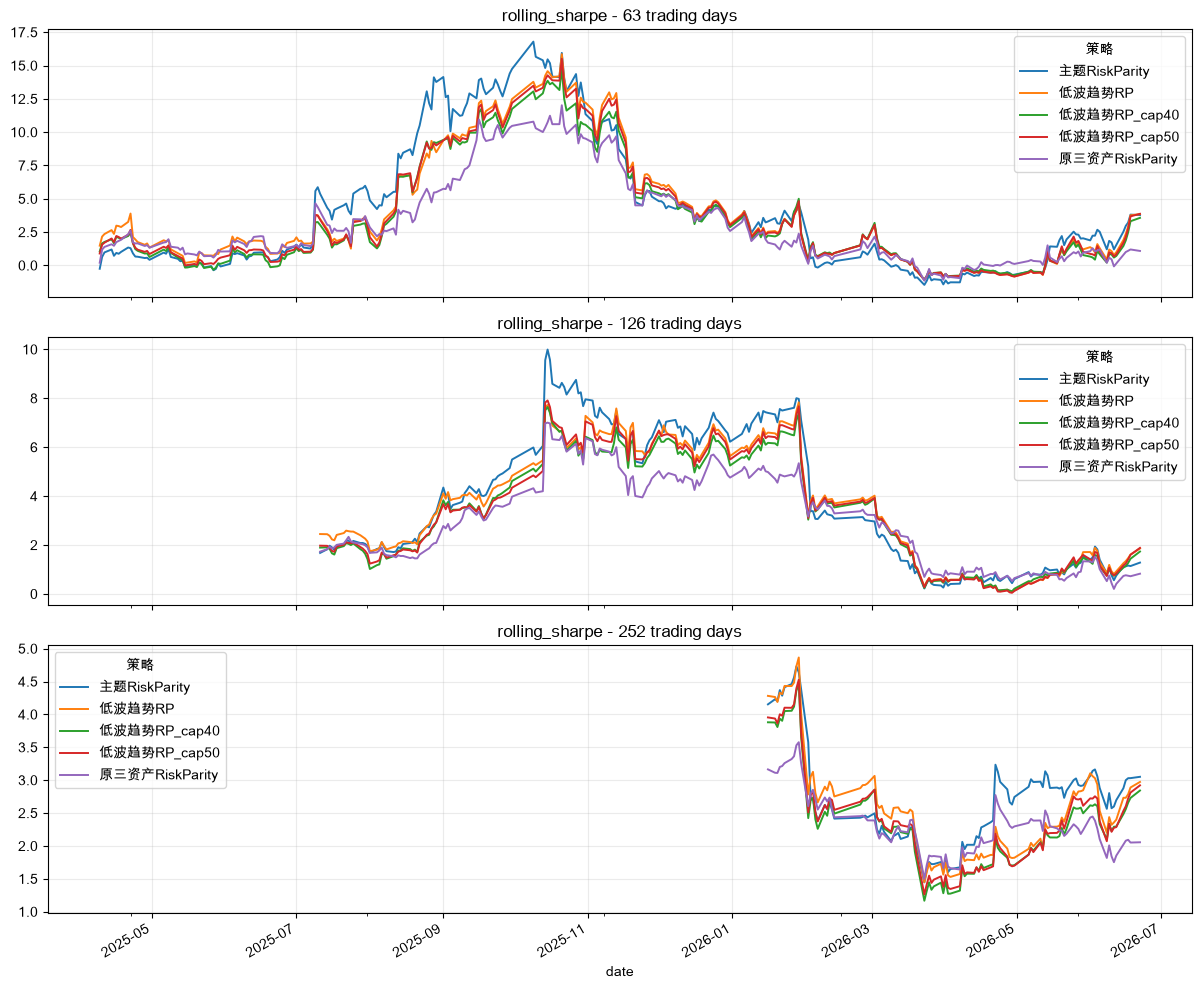

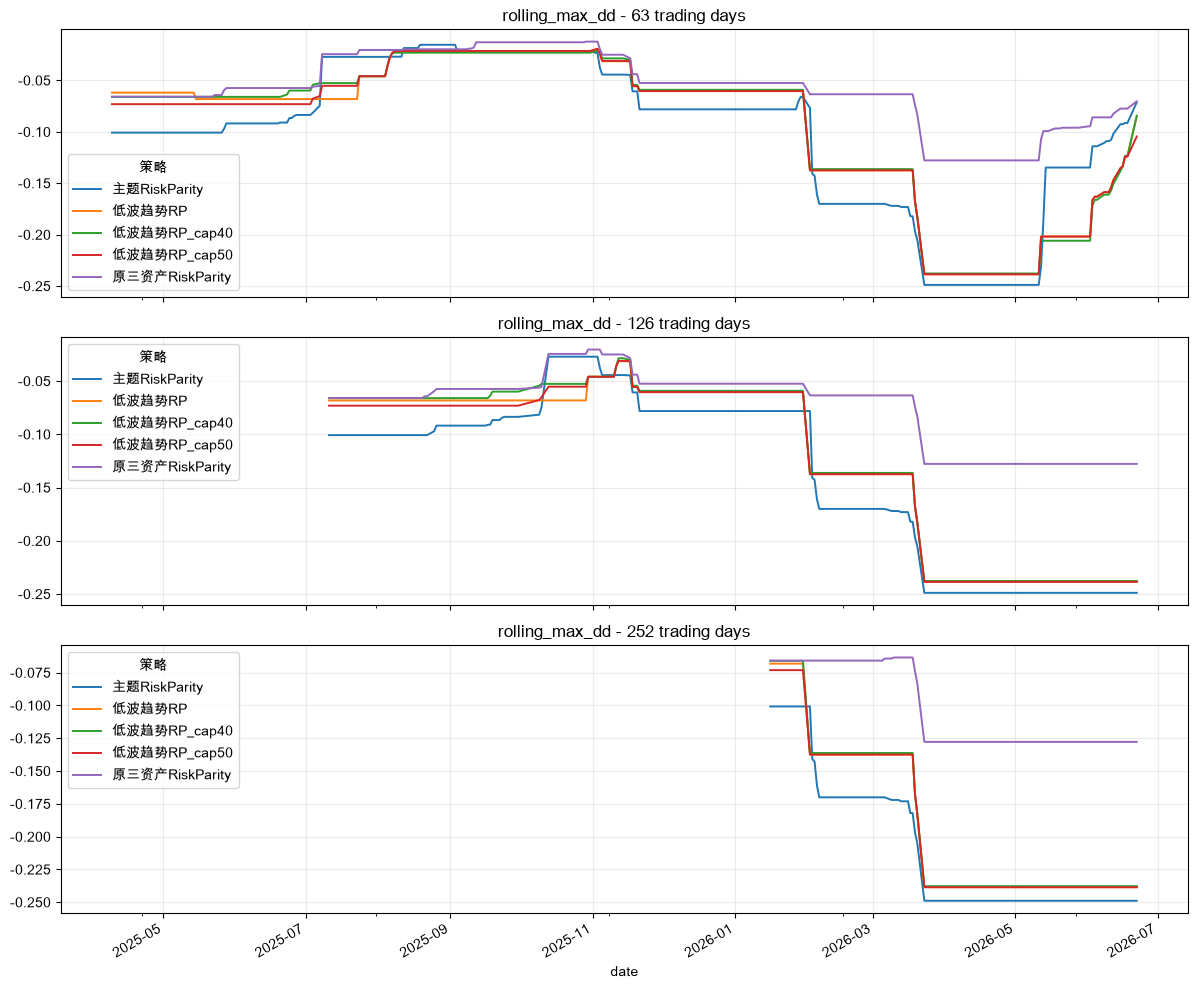

In [7]:
def rolling_metrics(r, window):
    r = r.dropna()
    rows = []
    for i in range(window - 1, len(r)):
        sub = r.iloc[i - window + 1 : i + 1]
        total = (1.0 + sub).prod() - 1.0
        vol = sub.std(ddof=1) * np.sqrt(TRADING_DAYS)
        ann = (1.0 + total) ** (TRADING_DAYS / len(sub)) - 1.0
        sharpe = ann / vol if pd.notna(vol) and vol > 0 else np.nan
        mdd = max_drawdown_from_returns(sub)
        rows.append({"date": sub.index[-1], "rolling_days": window, "rolling_return": total, "rolling_sharpe": sharpe, "rolling_max_dd": mdd})
    return pd.DataFrame(rows).set_index("date") if rows else pd.DataFrame()

focus_names = ["原三资产RiskParity", "主题RiskParity", "低波趋势RP", "低波趋势RP_cap50", "低波趋势RP_cap40"]
rolling_frames = []
for name in focus_names:
    r = base_portfolios[name]["returns"].loc["2025-01-01":]
    for window in [63, 126, 252]:
        rm = rolling_metrics(r, window)
        if rm.empty:
            continue
        rm["策略"] = name
        rolling_frames.append(rm.reset_index())
rolling_detail = pd.concat(rolling_frames, ignore_index=True)
rolling_detail.to_csv(OUTPUT_DIR / "rolling_detail.csv", index=False, encoding="utf-8-sig")

rolling_summary = rolling_detail.groupby(["策略", "rolling_days"]).agg(
    平均滚动收益=("rolling_return", "mean"),
    滚动收益胜率=("rolling_return", lambda x: (x > 0).mean()),
    平均滚动Sharpe=("rolling_sharpe", "mean"),
    滚动Sharpe为正比例=("rolling_sharpe", lambda x: (x > 0).mean()),
    最差滚动回撤=("rolling_max_dd", "min"),
).reset_index()
rolling_summary.to_csv(OUTPUT_DIR / "rolling_summary.csv", index=False, encoding="utf-8-sig")
display(rolling_summary.round(4))

for metric in ["rolling_return", "rolling_sharpe", "rolling_max_dd"]:
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    for ax, window in zip(axes, [63, 126, 252]):
        pivot = rolling_detail[rolling_detail["rolling_days"] == window].pivot(index="date", columns="策略", values=metric)
        pivot.plot(ax=ax, linewidth=1.4)
        ax.set_title(f"{metric} - {window} trading days")
        ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{metric}_rolling.png", dpi=160, bbox_inches="tight")
    plt.show()


## 7. Simple Out-of-Sample Parameter Validation

This is a modest check: rank parameter variants in 2025, then inspect how those same variants rank in 2026 YTD. It is not a full walk-forward optimizer, but it helps detect obvious parameter mining.


In [8]:
def low_vol_variant_name(ma, cap):
    cap_text = "uncapped" if cap is None else f"cap{int(cap*100)}"
    return f"LVT_MA{ma}_{cap_text}"

param_ports = {}
for ma in [60, 120, 180, 200]:
    for cap in [None, 0.60, 0.50, 0.40]:
        name = low_vol_variant_name(ma, cap)
        param_ports[name] = run_strategy(
            name,
            THEME_ASSETS,
            low_vol_trend_selector(THEME_ASSETS, ma_window=ma, mom_window=BASE_MOM, vol_window=BASE_LOW_VOL_WINDOW, top_n=BASE_TOP_N),
            rp_allocator(THEME_ASSETS, cap=cap),
            cost_bps=0.0,
        )

param_rows = []
for name, port in param_ports.items():
    for split_name, start, end in [("in_sample_2025", "2025-01-01", "2025-12-31"), ("oos_2026_ytd", "2026-01-01", None)]:
        r = window_slice(port["returns"], start, end)
        row = metrics_row(name, r, port["weights"], port["turnover"])
        row["split"] = split_name
        row["ma_window"] = int(name.split("_")[1].replace("MA", ""))
        row["cap"] = name.split("_")[2]
        param_rows.append(row)
param_metrics = pd.DataFrame(param_rows)

wide = param_metrics.pivot(index="策略", columns="split", values=["累计收益", "最大回撤", "夏普", "卡玛", "年化换手", "平均现金", "平均最大单资产权重"])
wide.columns = [f"{metric}_{split}" for metric, split in wide.columns]
wide = wide.reset_index()
for metric in ["累计收益", "夏普", "卡玛"]:
    wide[f"rank_2025_{metric}"] = wide[f"{metric}_in_sample_2025"].rank(ascending=False, method="min")
    wide[f"rank_2026_{metric}"] = wide[f"{metric}_oos_2026_ytd"].rank(ascending=False, method="min")
wide = wide.sort_values("rank_2025_夏普")
wide.to_csv(OUTPUT_DIR / "oos_parameter_validation.csv", index=False, encoding="utf-8-sig")
display(wide.round(4))

rank_corr = []
for metric in ["累计收益", "夏普", "卡玛"]:
    corr = wide[[f"rank_2025_{metric}", f"rank_2026_{metric}"]].corr(method="spearman").iloc[0, 1]
    rank_corr.append({"metric": metric, "spearman_rank_corr_2025_vs_2026": corr})
rank_corr_df = pd.DataFrame(rank_corr)
rank_corr_df.to_csv(OUTPUT_DIR / "oos_rank_correlation.csv", index=False, encoding="utf-8-sig")
display(rank_corr_df.round(4))


,策略,累计收益_in_sample_2025,累计收益_oos_2026_ytd,最大回撤_in_sample_2025,最大回撤_oos_2026_ytd,夏普_in_sample_2025,夏普_oos_2026_ytd,卡玛_in_sample_2025,卡玛_oos_2026_ytd,年化换手_in_sample_2025,...,平均现金_in_sample_2025,平均现金_oos_2026_ytd,平均最大单资产权重_in_sample_2025,平均最大单资产权重_oos_2026_ytd,rank_2025_累计收益,rank_2026_累计收益,rank_2025_夏普,rank_2026_夏普,rank_2025_卡玛,rank_2026_卡玛
14,LVT_MA60_cap60,0.7338,0.3043,-0.0639,-0.2673,4.6277,2.4098,12.1094,3.1339,5.4096,...,0.0000,0.0909,0.5011,0.4664,2.0,3.0,1.0,3.0,1.0,3.0
12,LVT_MA60_cap40,0.6953,0.3240,-0.0660,-0.2379,4.5089,2.6087,11.1033,3.7924,4.4913,...,0.0106,0.0909,0.3988,0.3636,4.0,1.0,2.0,1.0,2.0,1.0
13,LVT_MA60_cap50,0.6985,0.3121,-0.0731,-0.2630,4.3913,2.4819,10.0709,3.2821,5.2582,...,0.0000,0.0909,0.4714,0.4332,3.0,2.0,3.0,2.0,3.0,2.0
15,LVT_MA60_uncapped,0.7356,0.2867,-0.0866,-0.2942,4.2958,2.1355,8.9600,2.6569,5.9448,...,0.0000,0.0909,0.5361,0.5392,1.0,4.0,4.0,4.0,10.0,10.0
3,LVT_MA120_uncapped,0.6104,0.2474,-0.0681,-0.2385,3.8990,1.9007,9.4271,2.7646,6.6774,...,0.0000,0.0000,0.5057,0.5092,5.0,8.0,5.0,8.0,7.0,7.0
2,LVT_MA120_cap60,0.5841,0.2359,-0.0639,-0.2385,3.8321,1.7902,9.6179,2.6184,6.2537,...,0.0000,0.0000,0.4827,0.4924,6.0,11.0,6.0,11.0,6.0,11.0
7,LVT_MA180_uncapped,0.5841,0.2474,-0.0627,-0.2385,3.7712,1.9007,9.7929,2.7646,6.0857,...,0.0000,0.0000,0.5018,0.5092,7.0,8.0,7.0,8.0,4.0,7.0
11,LVT_MA200_uncapped,0.5841,0.2474,-0.0627,-0.2385,3.7712,1.9007,9.7929,2.7646,6.0857,...,0.0000,0.0000,0.5018,0.5092,7.0,8.0,7.0,8.0,4.0,7.0
6,LVT_MA180_cap60,0.5559,0.2359,-0.0639,-0.2385,3.6362,1.7902,9.1498,2.6184,5.6263,...,0.0000,0.0000,0.4830,0.4924,9.0,11.0,9.0,11.0,8.0,11.0
10,LVT_MA200_cap60,0.5559,0.2359,-0.0639,-0.2385,3.6362,1.7902,9.1498,2.6184,5.6263,...,0.0000,0.0000,0.4830,0.4924,9.0,11.0,9.0,11.0,8.0,11.0


,metric,spearman_rank_corr_2025_vs_2026
0,累计收益,0.6478
1,夏普,0.6687
2,卡玛,0.4299


## 8. Charts And Conclusion Inputs


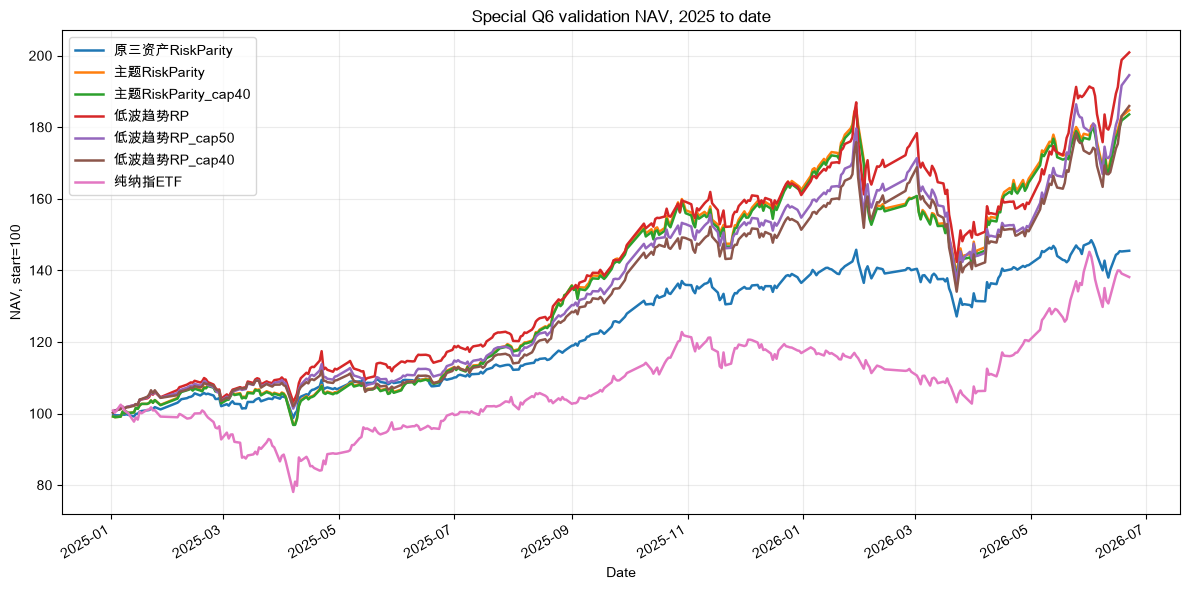

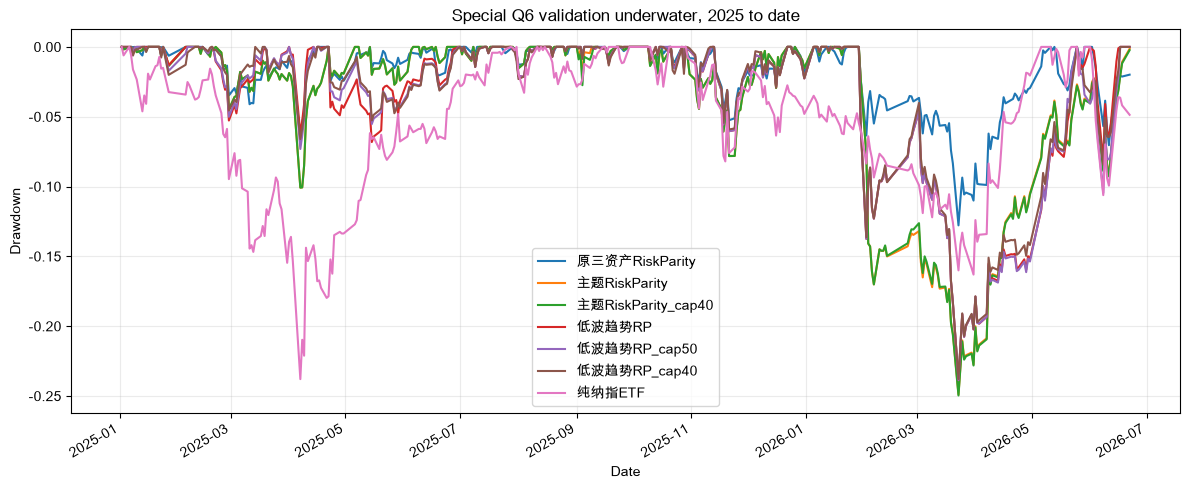

,window,historical_best,sharpe_best,calmar_best,lowest_drawdown,lowvol_uncapped_return,lowvol_cap50_return,theme_rp_return,baseline_return
0,2025_only,主题等权,低波趋势RP,低波趋势RP_cap60,60_40沪深300黄金,0.610360,0.547215,0.624540,0.364911
1,2026_ytd,低波趋势RP_cap50,低波趋势RP_cap50,纯纳指ETF,原三资产RiskParity,0.247432,0.257275,0.137295,0.065791
2,2025_to_date,低波趋势RP,低波趋势RP,低波趋势RP,原三资产RiskParity,1.008814,0.945275,0.847581,0.454710


In [9]:
# NAV and underwater charts for the main 2025-to-date validation set.
main_names = ["原三资产RiskParity", "主题RiskParity", "主题RiskParity_cap40", "低波趋势RP", "低波趋势RP_cap50", "低波趋势RP_cap40", "纯纳指ETF"]
main_returns = pd.DataFrame({name: base_portfolios[name]["returns"].loc["2025-01-01":] for name in main_names})
main_nav = main_returns.apply(nav_from_returns)
main_underwater = main_nav.apply(drawdown)

fig, ax = plt.subplots(figsize=(12, 6))
main_nav.plot(ax=ax, linewidth=1.8)
ax.set_title("theme-alpha-q1 validation NAV, 2025 to date")
ax.set_ylabel("NAV, start=100")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nav_validation_2025_to_date.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
main_underwater.plot(ax=ax, linewidth=1.5)
ax.set_title("theme-alpha-q1 validation underwater, 2025 to date")
ax.set_ylabel("Drawdown")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "underwater_validation_2025_to_date.png", dpi=160, bbox_inches="tight")
plt.show()

# Compact research summary for the note.
summary_rows = []
for window_name, out in window_outputs.items():
    s = out["summary"]
    summary_rows.append({
        "window": window_name,
        "historical_best": s["累计收益"].idxmax(),
        "sharpe_best": s["夏普"].idxmax(),
        "calmar_best": s["卡玛"].idxmax(),
        "lowest_drawdown": s["最大回撤"].idxmax(),
        "lowvol_uncapped_return": s.loc["低波趋势RP", "累计收益"],
        "lowvol_cap50_return": s.loc["低波趋势RP_cap50", "累计收益"],
        "theme_rp_return": s.loc["主题RiskParity", "累计收益"],
        "baseline_return": s.loc["原三资产RiskParity", "累计收益"],
    })
research_summary = pd.DataFrame(summary_rows)
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(research_summary)
